In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

In [2]:
df_kinetic = pd.read_pickle(f'files/processed/all_distributions_151025.pkl')
df_grouped_kinetic = pd.read_pickle(f'files/processed/all_distributions_summary_151025.pkl')

df_kinetic_flow = pd.read_pickle(f'files/processed/all_distributions_151025_flow.pkl')
df_grouped_kinetic_flow = pd.read_pickle(f'files/processed/all_distributions_summary_151025_flow.pkl')

boltzman_distr_df = pd.read_pickle('files/processed/boltzman_distr_071025_16.pkl')
df_grouped_boltzman = pd.read_pickle('files/processed/boltzman_distr_summary_071025_16.pkl')

ts = pd.DataFrame()
for temperature in [300, 360, 390, 420]:
    tst = pd.read_pickle(f'files/processed/ts_century_run_c16_temperature_{temperature}_pressure_1.pkl')
    tst['temperature'] = temperature
    tst = tst.reset_index(names=['time'])
    ts = pd.concat([ts, tst], ignore_index=True)

ts = ts.melt(id_vars=['time', 'temperature'], var_name='olefin', value_name='concentration')
ts['n'] = ts['olefin'].apply(lambda x: int(x[1:]))

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_4686/1085746568.py:30: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('300 nm flow mode', '10$\mu$m flow mode', 'cluster particles\n100$\mu$m flow mode', r'$\infty$ nm'), axs):
/tmp/ipykernel_4686/1085746568.py:30: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('300 nm flow mode', '10$\mu$m flow mode', 'cluster particles\n100$\mu$m flow mode', r'$\infty$ nm'), axs):


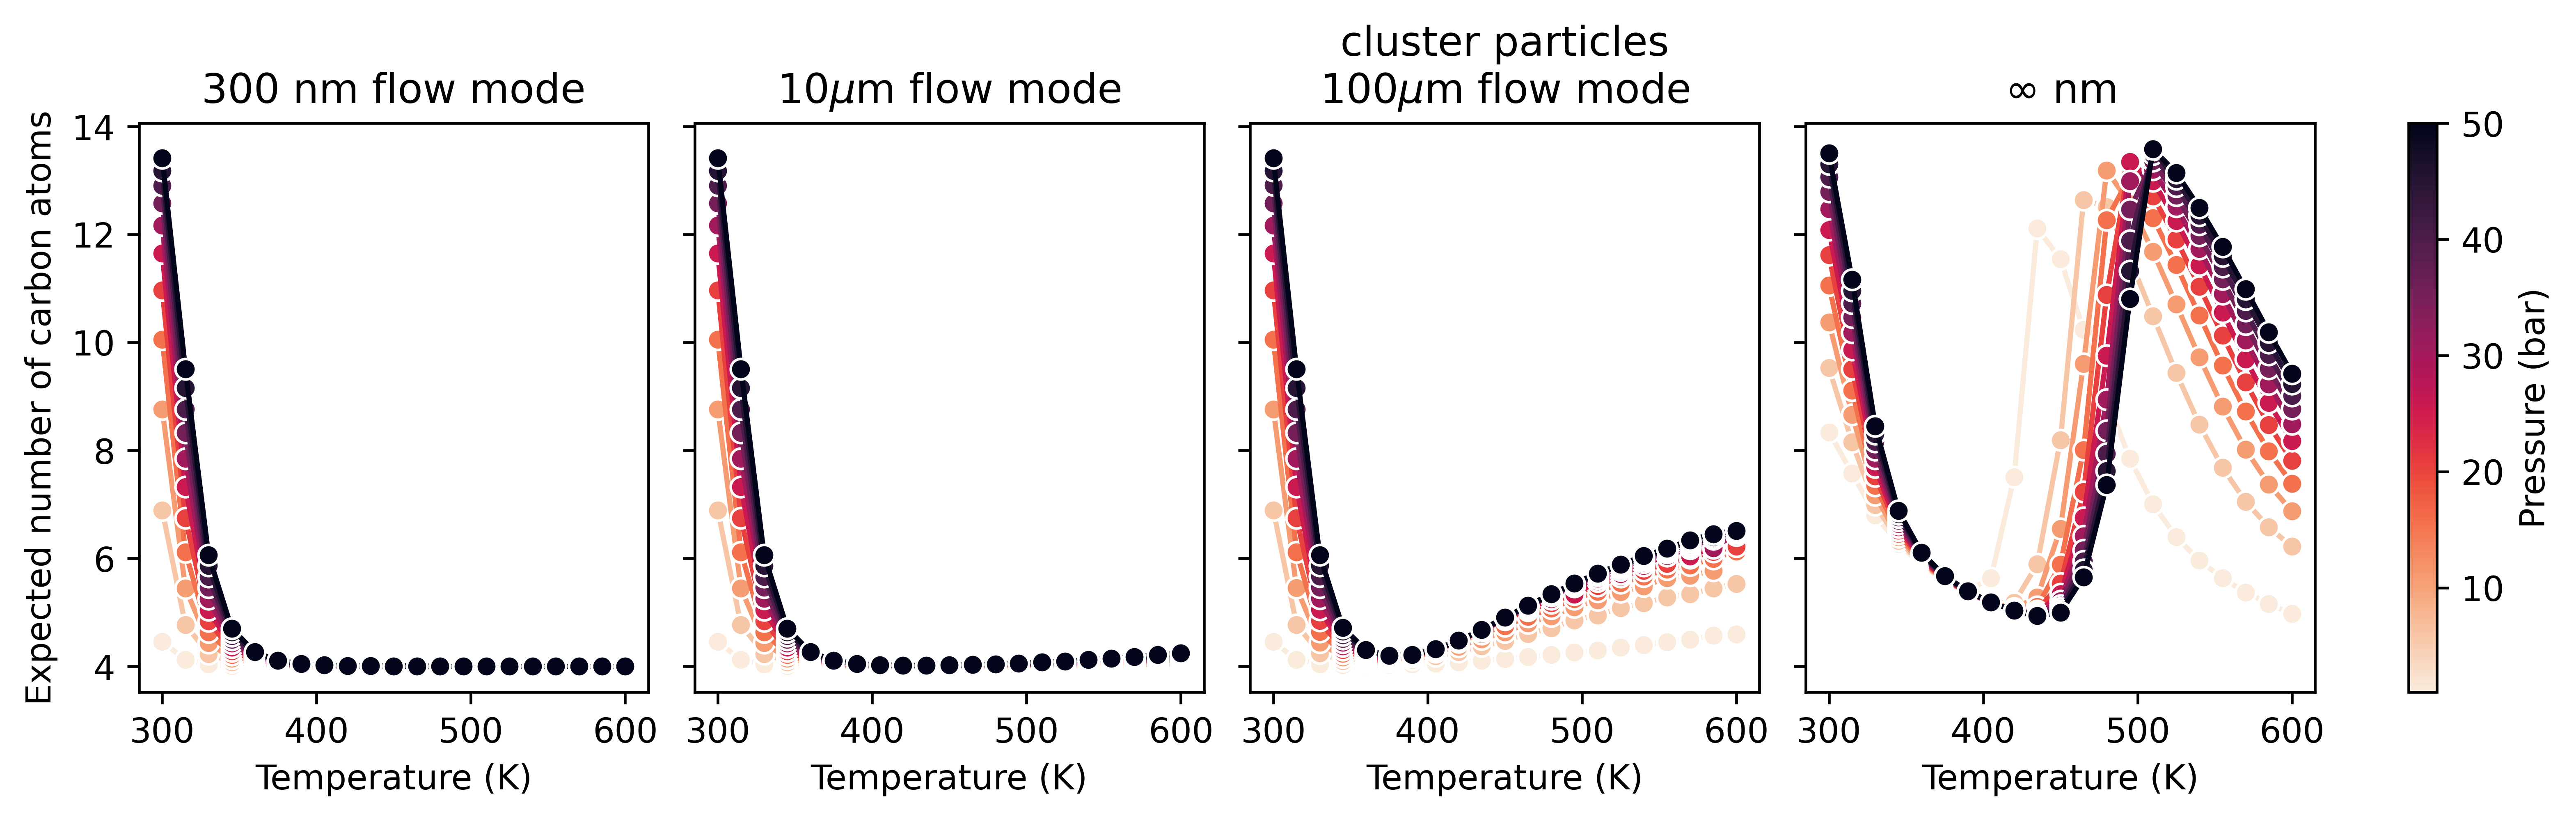

In [25]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3), dpi=600, sharey=True)

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, ax) in enumerate([
    (300, True, True, axs[0]),
    (10000, True, True, axs[1]),
    (int(1e5), True, True, axs[2]),
    (300, False, False, axs[3]),
]):
    if not is_stream:
        df = df_grouped_kinetic
    else:
        df = df_grouped_kinetic_flow

    data = df.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream} and cat_conc == 0.01')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('300 nm flow mode', '10$\mu$m flow mode', 'cluster particles\n100$\mu$m flow mode', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En.png", bbox_inches="tight")

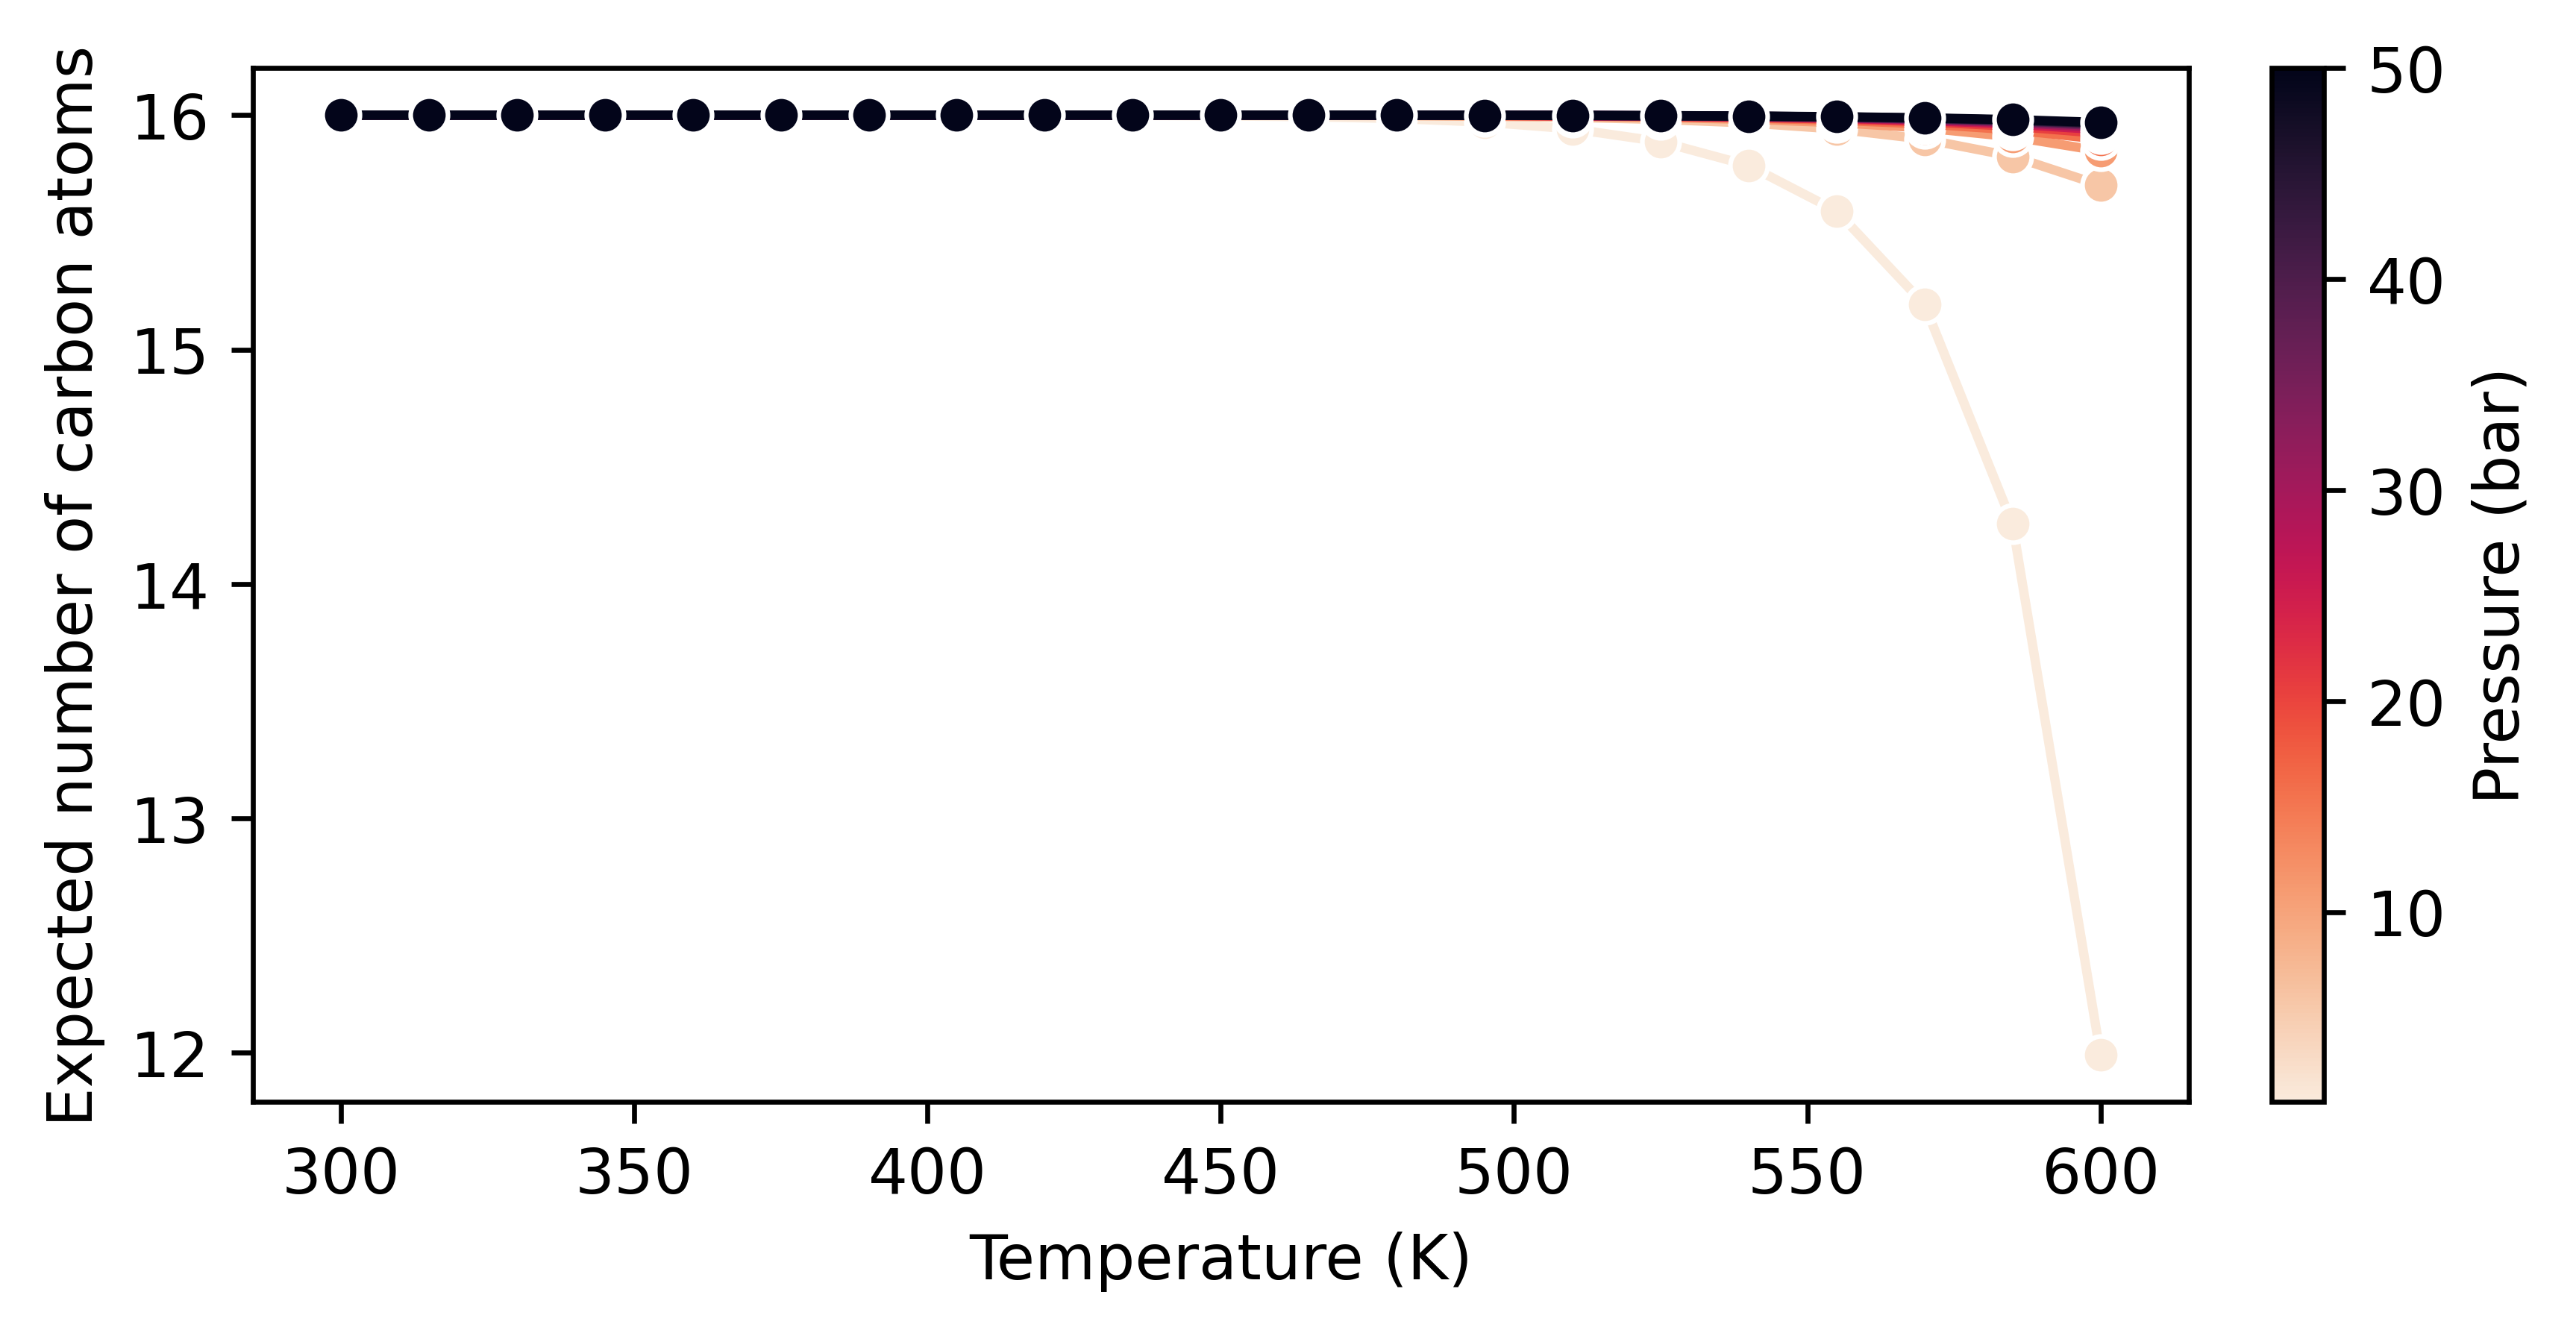

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3), dpi=600, sharey=True)

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)


data = df_grouped_boltzman
# Sort so higher pressure values are plotted first (smaller pressures above)
sns.lineplot(
    data=data,
    x='temperature', y='expected_n', hue='pressure',
    hue_order=sorted(data['pressure'].unique(), reverse=False),
    hue_norm=norm,
    marker='o', ax=ax,
    palette=sns.color_palette(cmap, as_cmap=True),
    
)


ax.set_xlabel('Temperature (K)')
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()
ax.set_title('')

ax.set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_boltzmann_En.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_boltzmann_En.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_boltzmann_En.png", bbox_inches="tight")

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_4686/802449853.py:30: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('300 nm batch mode', '10$\mu$m batch mode', '100$\mu$m batch mode', r'$\infty$ nm'), axs):
/tmp/ipykernel_4686/802449853.py:30: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('300 nm batch mode', '10$\mu$m batch mode', '100$\mu$m batch mode', r'$\infty$ nm'), axs):


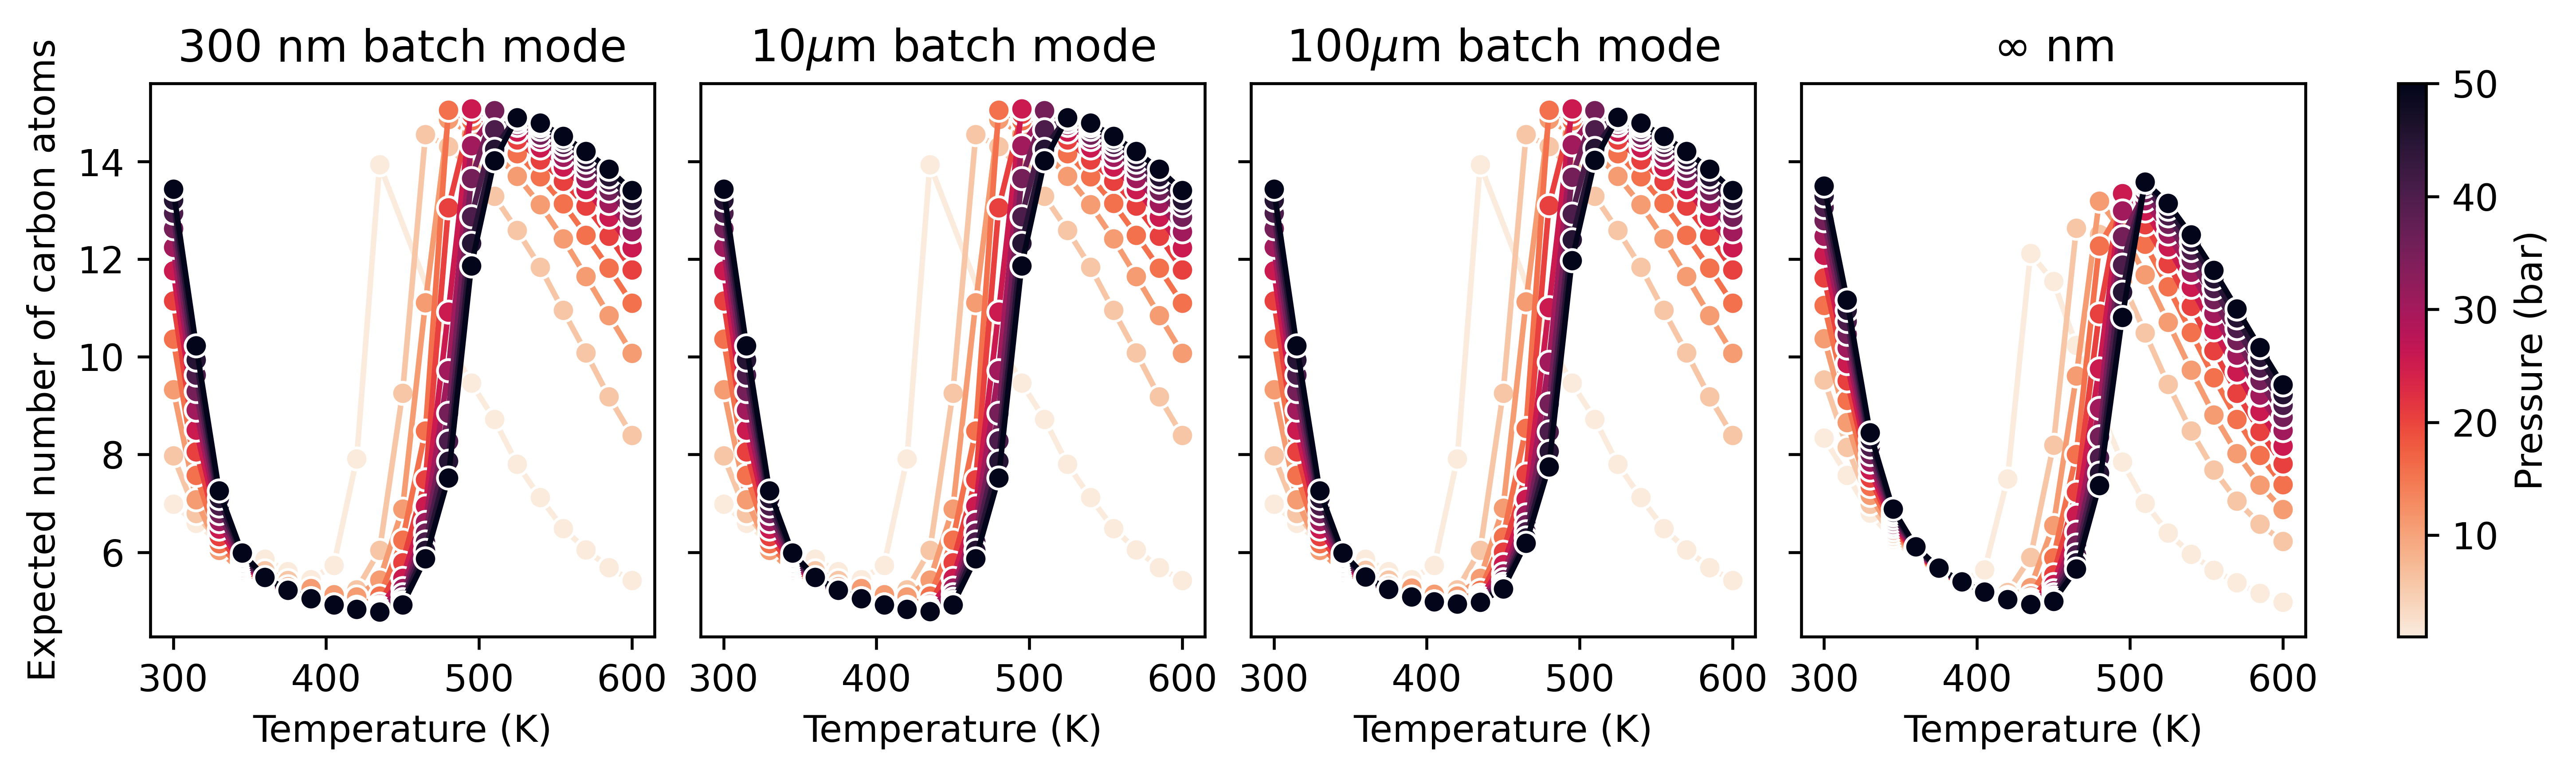

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(11, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, ax) in enumerate([
    (300, True, False, axs[0]),
    (10000, True, False, axs[1]),
    (int(1e5), True, False, axs[2]),
    (300, False, False, axs[3]),
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('300 nm batch mode', '10$\mu$m batch mode', '100$\mu$m batch mode', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En_SI.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI.png", bbox_inches="tight")

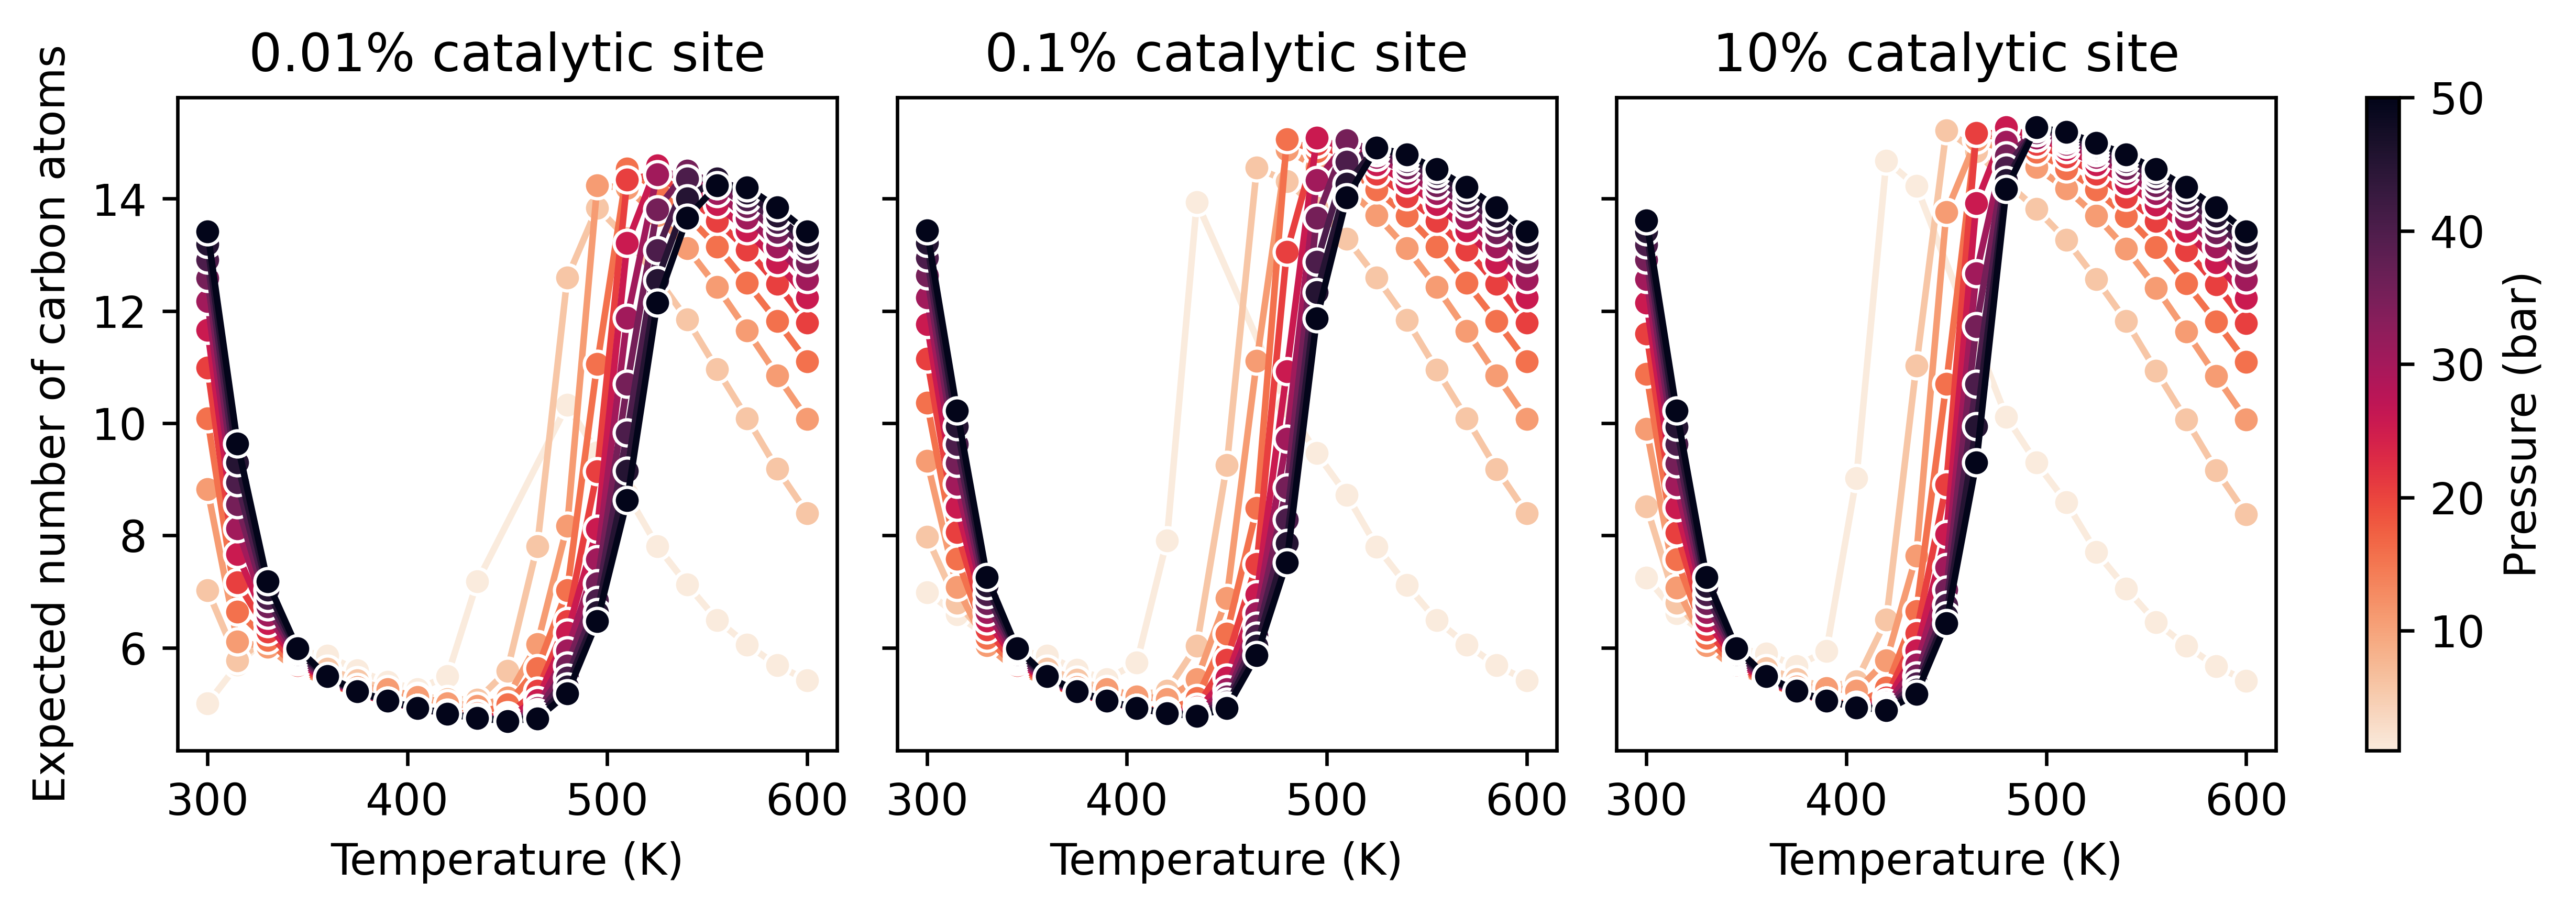

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic#.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, cat_conc, ax) in enumerate([
    (1000, True, False, 0.001, axs[0]),
    (1000, True, False, 0.01, axs[1]),
    (1000, True, False, 0.1, axs[2]),
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream} and cat_conc == {cat_conc}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('0.01% catalytic site', '0.1% catalytic site', '10% catalytic site'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En_SI_cat_conc_batch.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_batch.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_batch.png", bbox_inches="tight")

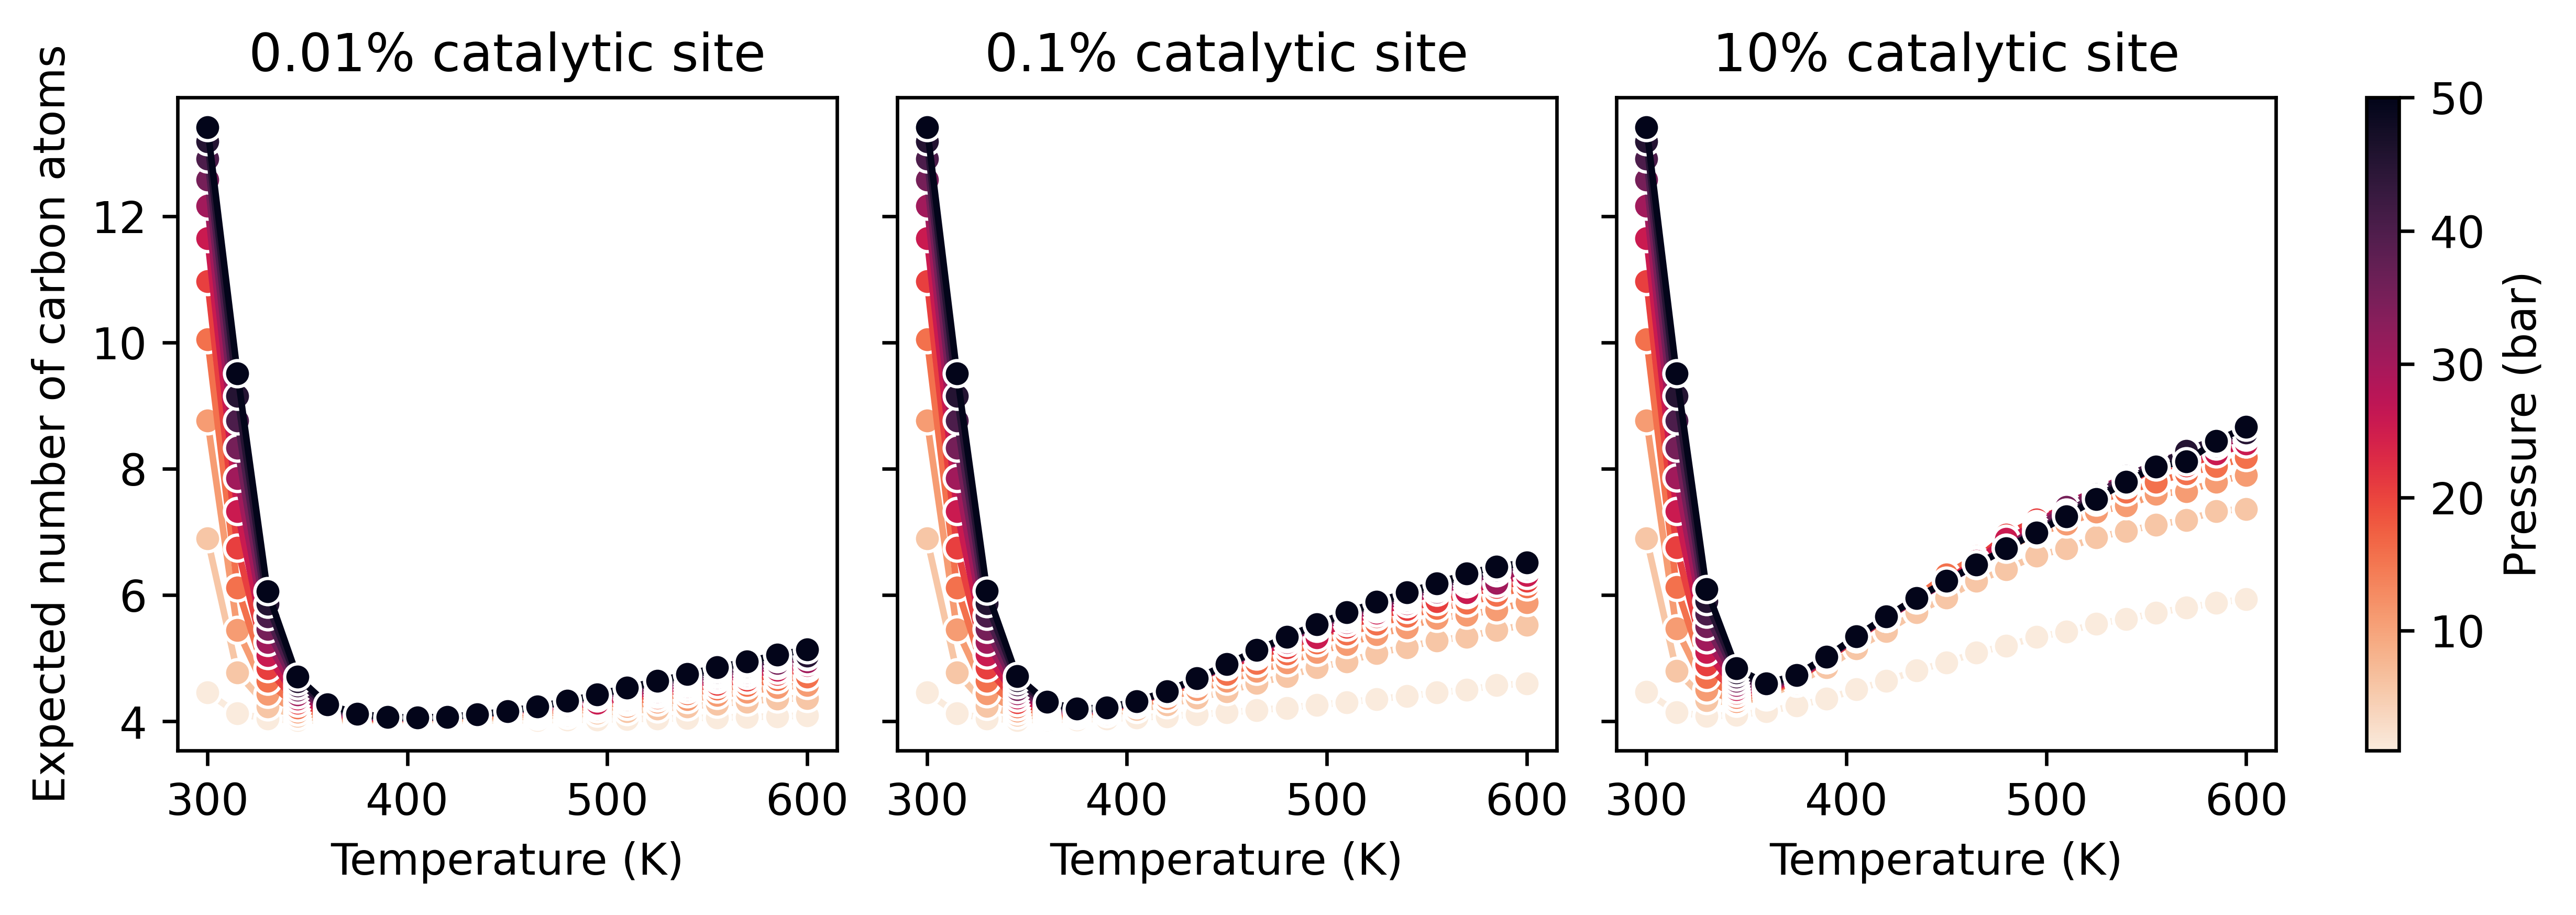

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic#.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, cat_conc, ax) in enumerate([
    (int(1e5), True, True, 0.001, axs[0]),
    (int(1e5), True, True, 0.01, axs[1]),
    (int(1e5), True, True, 0.1, axs[2]),
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream} and cat_conc == {cat_conc}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('0.01% catalytic site', '0.1% catalytic site', '10% catalytic site'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En_SI_cat_conc_flow.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_flow.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_flow.png", bbox_inches="tight")

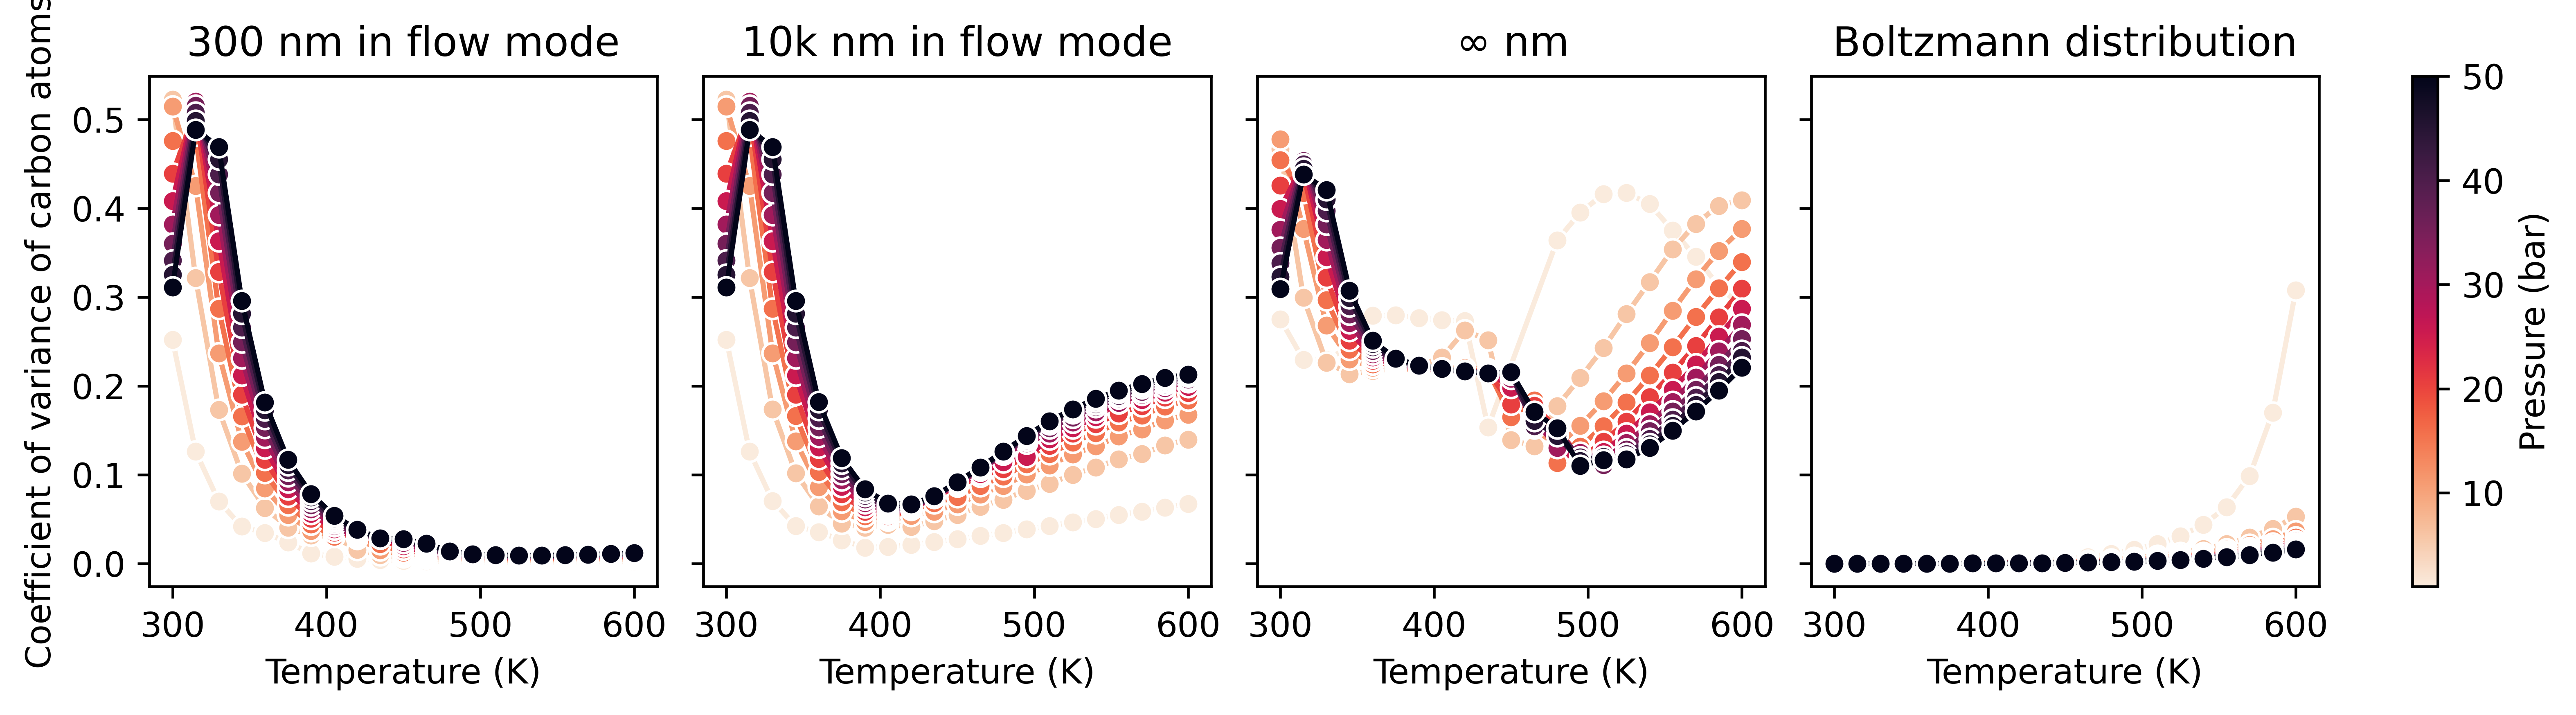

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(12, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, ax) in enumerate([
    (300, True, True, axs[0]),
    (10000, True, True, axs[1]),
    (300, True, False, axs[2]),
    (None, None, None, axs[3])
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    sns.lineplot(
        data=data,
        x='temperature', y='coefficient_variance', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('300 nm in flow mode', '10k nm in flow mode', r'$\infty$ nm', 'Boltzmann distribution'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Coefficient of variance of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_CV.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_CV.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_CV.png", bbox_inches="tight")

In [12]:
df_grouped_kinetic.groupby(['particle_size', 'is_stream']).count()

temperature  pressure  diffusion  cat_conc  \
particle_size is_stream                                               
300           False             1380      1380       1380      1380   
              True               687       687        687       687   
1000          False             1380      1380       1380      1380   
              True               690       690        690       690   
10000         False             1380      1380       1380      1380   
              True               693       693        693       693   
100000        False             1380      1380       1380      1380   
              True               692       692        692       692   
1000000       False             1380      1380       1380      1380   
              True               666       666        666       666   

                         expected_n  expected_n2  variance_n  std_n  \
particle_size is_stream                                               
300           False            1380         1380        1380   1380   
              True              687          687         687    687   
1000          False            1380         1380        1380   1380   
              True              690          690         690    690   
10000         False            1380         1380        1380   1380   
              True              693          693         693    693   
100000        False            1380         1380        1380   1380   
              True              692          692         692    692   
1000000       False            1380         1380        1380   1380   
              True              666          666         666    666   

                         coefficient_variance  
particle_size is_stream                        
300           False                      1380  
              True                        687  
1000          False                      1380  
              True                        690  
10000         False                      1380  
              True                        693  
100000        False                      1380  
              True                        692  
1000000       False                      1380  
              True                        666

<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_4686/477963829.py:23: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_xticklabels(['300', '10$\mu$m', 'cluster 100$\mu$m'])
/tmp/ipykernel_4686/477963829.py:23: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_xticklabels(['300', '10$\mu$m', 'cluster 100$\mu$m'])
/tmp/ipykernel_4686/477963829.py:24: SyntaxWarning: invalid escape sequence '\m'
  axs[1].set_xticklabels(['300', '10$\mu$m', 'cluster 100$\mu$m'])
/tmp/ipykernel_4686/477963829.py:24: SyntaxWarning: invalid escape sequence '\m'
  axs[1].set_xticklabels(['300', '10$\mu$m', 'cluster 100$\mu$m'])


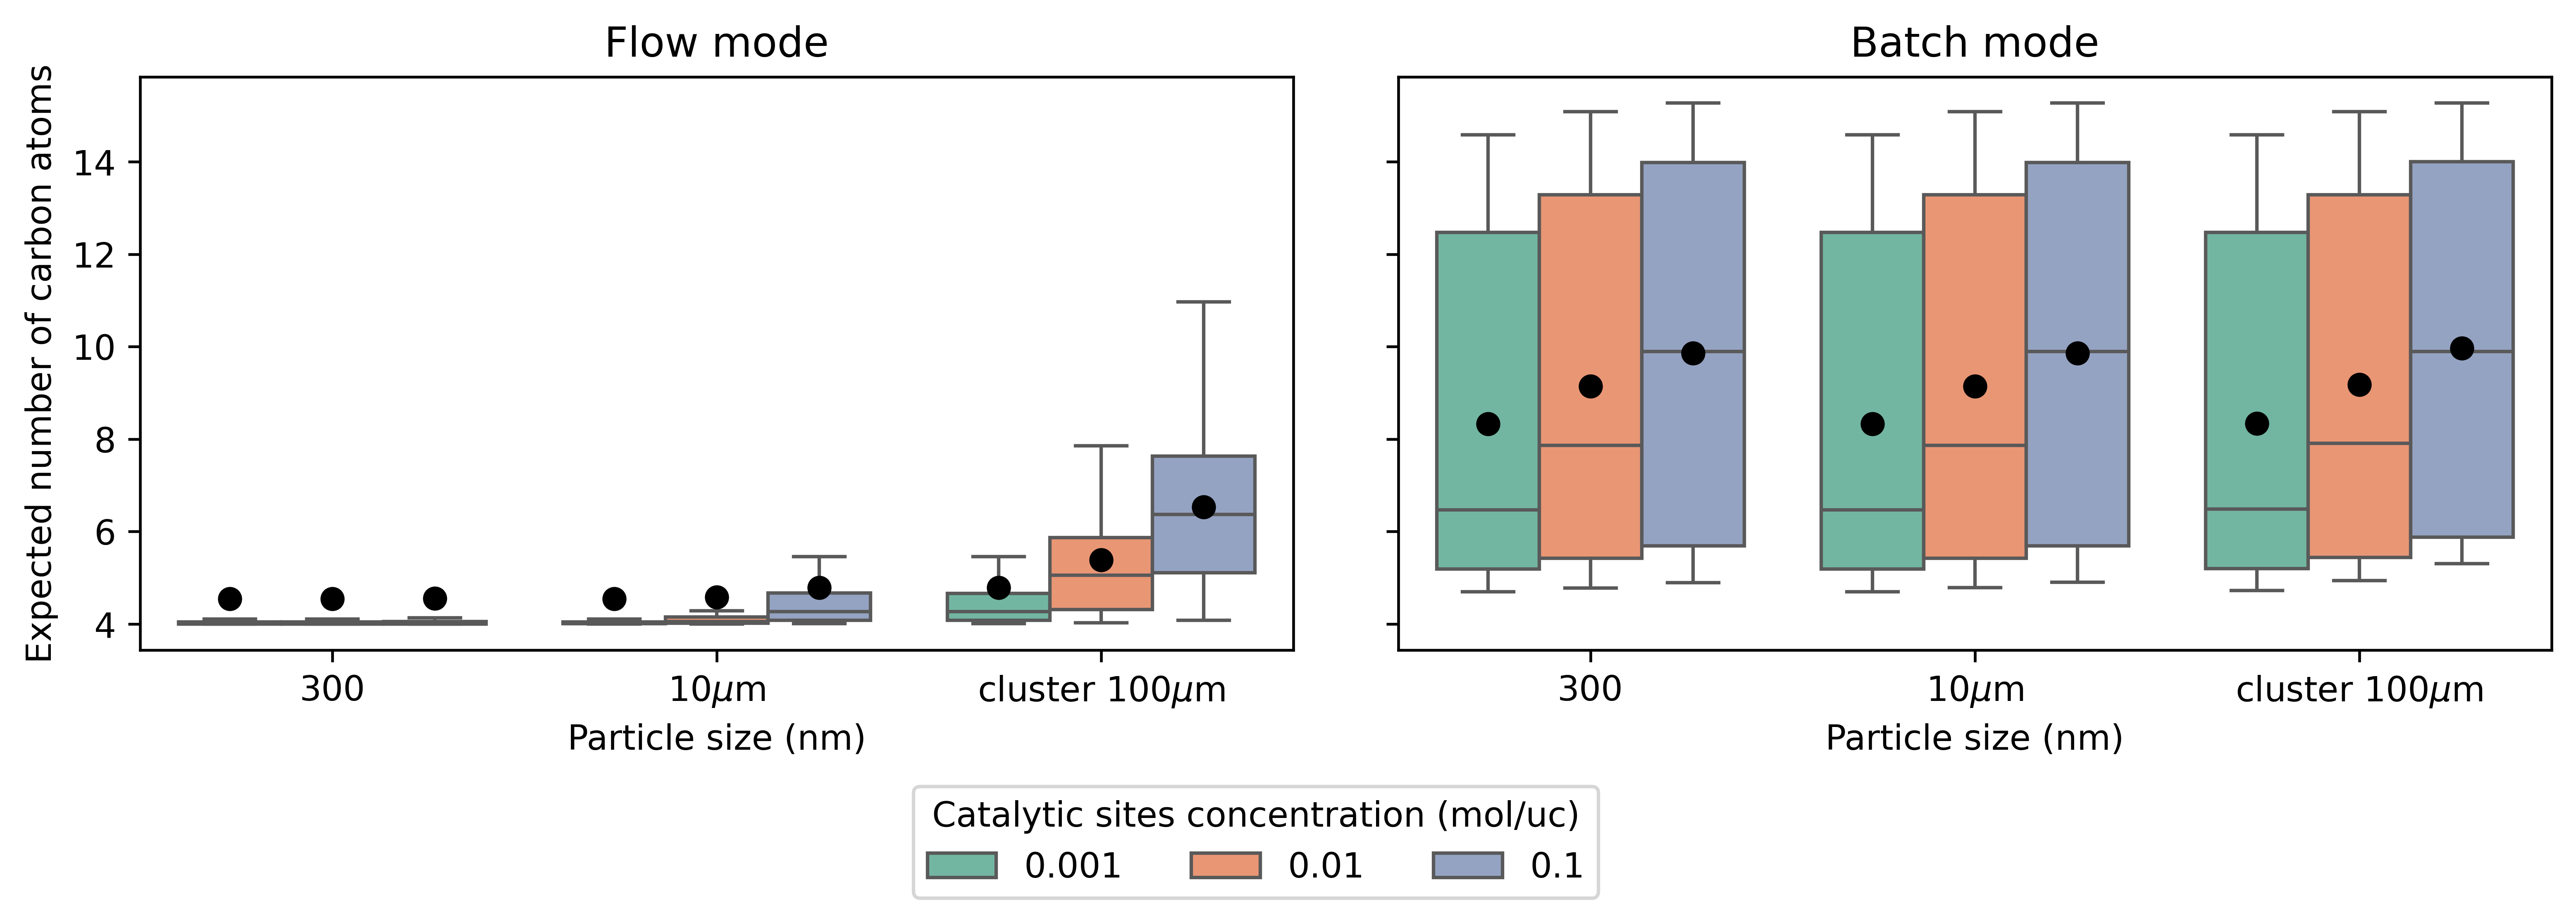

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3), sharey=True, dpi=600)
meanprops = {'marker':'o', 'markerfacecolor':'black', 'markeredgecolor':'black', 'markersize':6}

sns.boxplot(data=df_grouped_kinetic_flow.query('is_stream and particle_size>50  and particle_size < 1e6'), x='particle_size', 
            palette='Set2', showmeans=True, meanprops=meanprops, showfliers=False,
            y='expected_n', hue='cat_conc', ax=axs[0])

sns.boxplot(data=df_grouped_kinetic.query('not is_stream and diffusion and particle_size>50 and particle_size != 1000 and particle_size < 1e6'), 
            palette='Set2', showmeans=True, meanprops=meanprops,
            x='particle_size', y='expected_n', hue='cat_conc', ax=axs[1])

axs[0].set_title('Flow mode')
axs[1].set_title('Batch mode')

axs[0].set_ylabel('Expected number of carbon atoms')
for ax in axs:
    ax.set_xlabel('Particle size (nm)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

axs[0].set_xticklabels(['300', '10$\mu$m', 'cluster 100$\mu$m'])
axs[1].set_xticklabels(['300', '10$\mu$m', 'cluster 100$\mu$m'])
# axs[1].set_ylim(3, 12)
fig.legend(handles, labels, loc='upper center', title='Catalytic sites concentration (mol/uc)', 
           bbox_to_anchor=(0.5, -0.05), ncol=len(labels))



fig.savefig("files/plots/distribution_En_vs_psize.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_vs_psize.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_vs_psize.png", bbox_inches="tight")

In [14]:
palette = sns.color_palette("Greens", n_colors=10)[2:]
palette = ['#f7fcf5','#e5f5e0','#c7e9c0','#a1d99b','#74c476','#41ab5d','#238b45','#006d2c','#00441b'][1:]

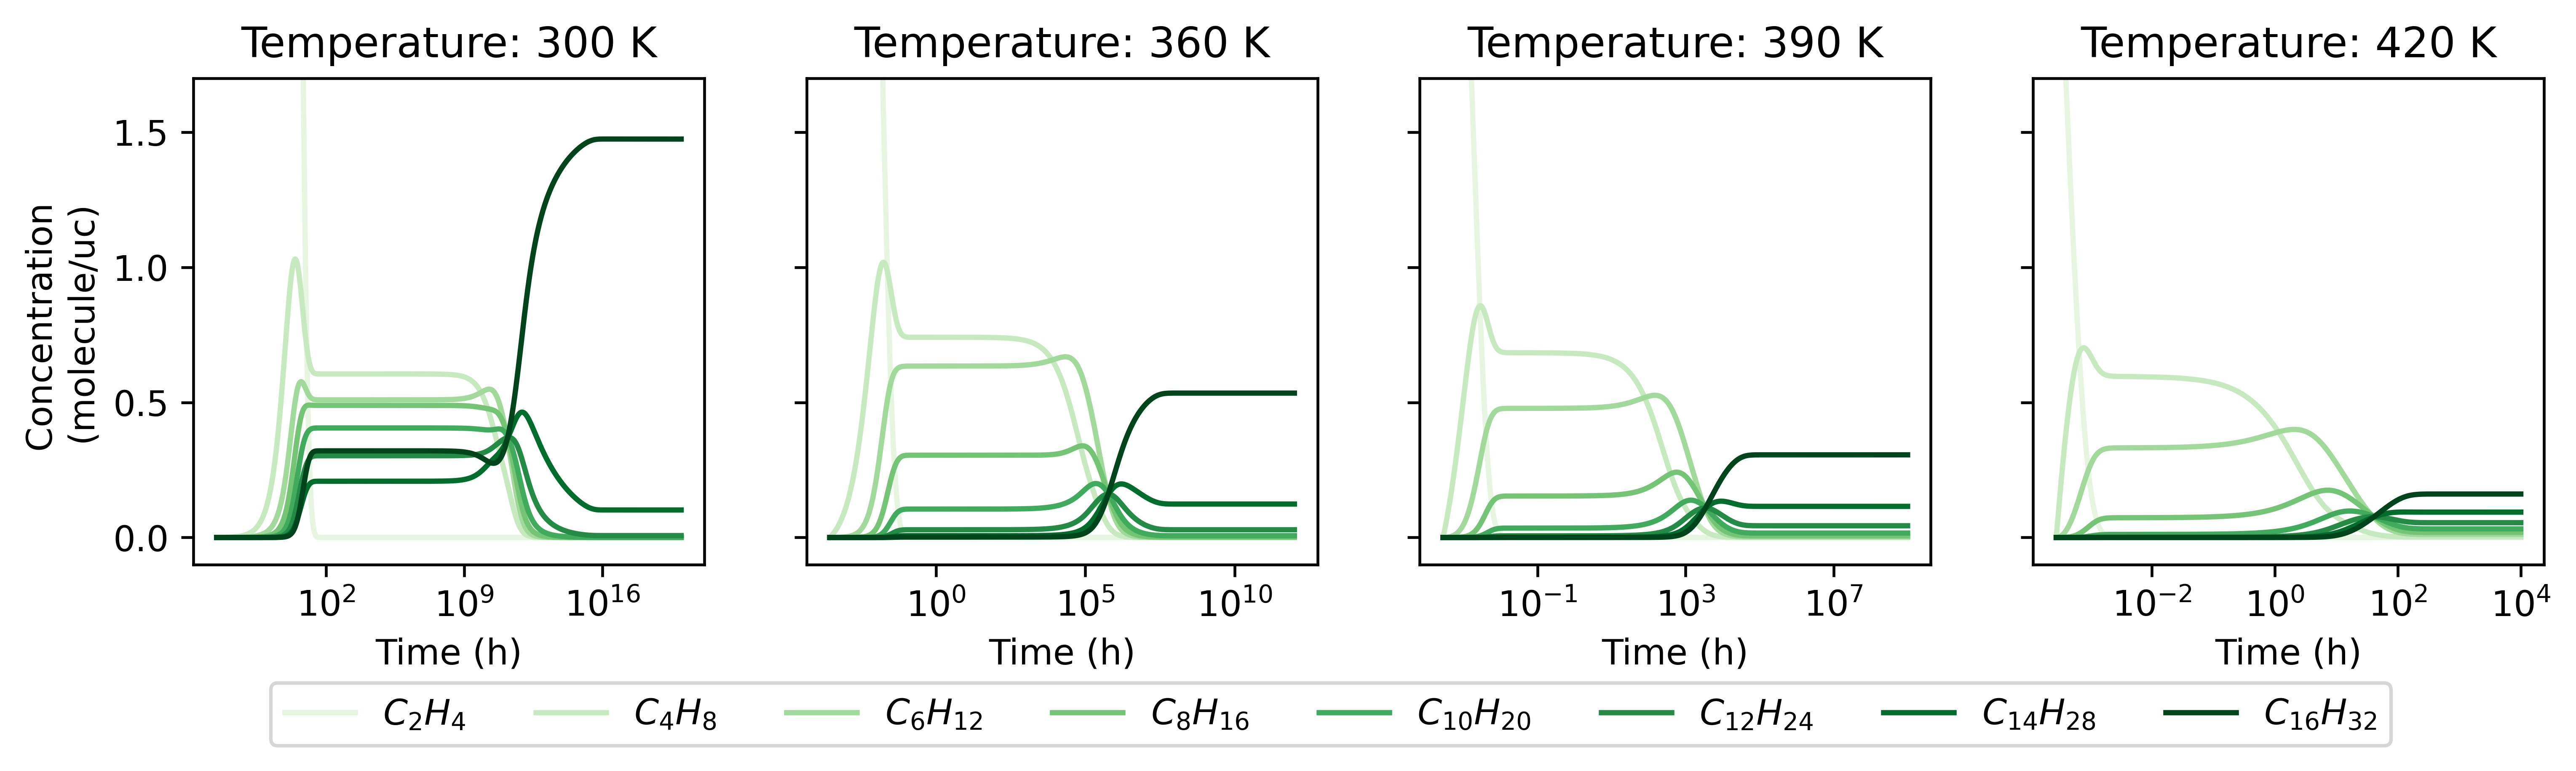

In [11]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 4, figsize=(12, 2.5), dpi=600, sharey=True)

sns.lineplot(data=ts[ts['temperature'] == 300], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[0])
sns.lineplot(data=ts[ts['temperature'] == 360], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[1], legend=False)
sns.lineplot(data=ts[ts['temperature'] == 390], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[2], legend=False)

sns.lineplot(data=ts[ts['temperature'] == 420], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[3], legend=False)

axs[0].set_title('Temperature: 300 K')
axs[1].set_title('Temperature: 360 K')
axs[2].set_title('Temperature: 390 K')
axs[3].set_title('Temperature: 420 K')
axs[0].set_ylabel('Concentration \n(molecule/uc)')
axs[0].set_ylim(-0.1, 1.7)
for ax in axs:
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Concentration \n(molecule/uc)')
    ax.set_xscale('log')

handles, labels = axs[0].get_legend_handles_labels()
axs[0].legend_.remove()

labels = [f'$C_{{{label}}}H_{{{2*int(label)}}}$' for label in labels]
fig.legend(handles, labels, bbox_to_anchor=(0.5, -0.05), 
           loc='upper center', ncol=8)

fig.savefig("files/plots/time_evaluation.pdf", bbox_inches="tight")
fig.savefig("files/plots/time_evaluation.svg", bbox_inches="tight")
fig.savefig("files/plots/time_evaluation.png", bbox_inches="tight")